# Analysis for the Project: Debt-Based License Suspension

## The Main Questions:
- What are the reasons for license suspensions? [Jassim]
- What % are not falling under safety related? [Rachel, Alberto]
- What % are debt based? [Sarah]
- How many people lose their license over nothing dangerous? [Yuan, Ethan]

In [1]:
%pip install python-calamine polars numpy pandas -U

   ---------------------------------------- 0.0/26.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/26.2 MB ? eta -:--:--
   ---------------------------------------- 0.1/26.2 MB 871.5 kB/s eta 0:00:30
    --------------------------------------- 0.6/26.2 MB 5.4 MB/s eta 0:00:05
   -- ------------------------------------- 1.4/26.2 MB 9.9 MB/s eta 0:00:03
   --- ------------------------------------ 2.5/26.2 MB 13.3 MB/s eta 0:00:02
   ---- ----------------------------------- 3.1/26.2 MB 14.0 MB/s eta 0:00:02
   ------ --------------------------------- 4.5/26.2 MB 15.2 MB/s eta 0:00:02
   -------- ------------------------------- 5.6/26.2 MB 16.9 MB/s eta 0:00:02
   --------- ------------------------------ 6.2/26.2 MB 15.9 MB/s eta 0:00:02
   ----------- ---------------------------- 7.8/26.2 MB 17.8 MB/s eta 0:00:02
   ------------- -------------------------- 8.9/26.2 MB 18.4 MB/s eta 0:00:01
   --------------- ------------------------ 10.2/26.2 MB 19.2 MB/s eta 0:00:01
  

In [2]:
import numpy as np
import polars as pl
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

data_path = pathlib.Path().cwd().parent / "data"
img_path = pathlib.Path().cwd().parent / "img"

In [3]:
reinstatement_path = pathlib.Path.cwd().parent.joinpath('data', r'Reinstatement_information_Part_2 (1).xlsx')

reinstatement = pl.from_dataframe(
    pd.concat([
        t1 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'flngAccountKey']), 
        t3 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'flngAccountKey'])
    ])
)

assert(reinstatement.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

print(reinstatement.shape)
reinstatement.head()

(148199, 6)


Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
i64,str,str,str,str,str
2020,"""NON-PAYMENT OF…","""Indefinite""","""1072""",null,null
2020,"""PROPERTY DAMAG…","""Indefinite""","""714""",null,null
2020,"""NRVC Withdrawa…","""Indefinite""","""1191""",null,null
2020,"""NRVC Withdrawa…","""Indefinite""","""924""",null,null
2020,"""94C35 __ PRESE…","""Definite""","""365""","""PD_GRA""","""Grafton Police…"


In [4]:
reinstatement.null_count()

Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
u32,u32,u32,u32,u32,u32
0,0,12,0,119770,119770


In [5]:
suspension_path = pathlib.Path.cwd().parent.joinpath('data', r'Suspension_information_Part_1 (1).xlsx')

suspension = pl.from_dataframe(
    pd.concat([
        t1 := pd.read_excel(suspension_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(suspension_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'Sanction Type']), 
        t3 := pd.read_excel(suspension_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'Sanction Type'])
    ])
)[['Year', 'Description', 'Term']]

assert(suspension.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

print(suspension.shape)
suspension.head()

(342783, 3)


Year,Description,Term
i64,str,str
2020,"""Operating Unde…","""Definite"""
2020,"""Operating Unde…","""Definite"""
2020,"""Operating Unde…","""Definite"""
2020,"""Ignition Inter…","""Indefinite"""
2020,"""Operating Unde…","""Definite"""


In [6]:
sus_by_year = suspension.to_pandas().groupby(['Year', 'Description']).size()
pd.DataFrame(sus_by_year)

0
Year Description                                           
2020 A20 - DUI of alcohol or drugs                        1
     A60 - Underage DUI BAC >=.02                         6
     A61 - Unge Admin DUI BAC >=.02                      12
     ADMIN PER SE                                      2802
     B01 - Hit & run after accident                       8
...                                                     ...
2022 USE MV WITHOUT AUTHORITY c90 §24(2)(a)             123
     USE MV WITHOUT AUTHORITY, 2ND OFF. c90 §24(2)(a)     7
     USE MV WITHOUT AUTHORITY, 3RD OFF. c90 §24(2)(a)     2
     VANDALIZE PROPERTY c266 §126A                        6
     Youth Alcohol Program Suspension                   195

[396 rows x 1 columns]

In [7]:
cur_suspended_path = pathlib.Path.cwd().parent.joinpath('data', r'Currently_Suspended_information_Part_3_as_of_12082_022 (1).xlsx')
cur_suspended = pl.read_excel(cur_suspended_path, engine='calamine')
print(cur_suspended.shape)
cur_suspended.head()

(693100, 5)


Description,Term,Days Sus/Rev,Authority,Issuing Agency
str,str,str,str,str
"""COURT DEFAULT""","""Indefinite""","""INDEFINITE""",null,null
"""W00 - Non-ACD …","""Indefinite""","""INDEFINITE""",null,null
"""Ignition Inter…","""Indefinite""","""INDEFINITE""",null,null
"""W00 - Non-ACD …","""Indefinite""","""INDEFINITE""",null,null
"""FSU __ 5 SURCH…","""Indefinite""","""INDEFINITE""",null,null


Description
PAYMENT DEFAULT                94842
Major Disqualification         89586
Three Surchargeable Events     78437
WARRANT                        56358
COURT DEFAULT                  50451
Other                         323426
dtype: int64

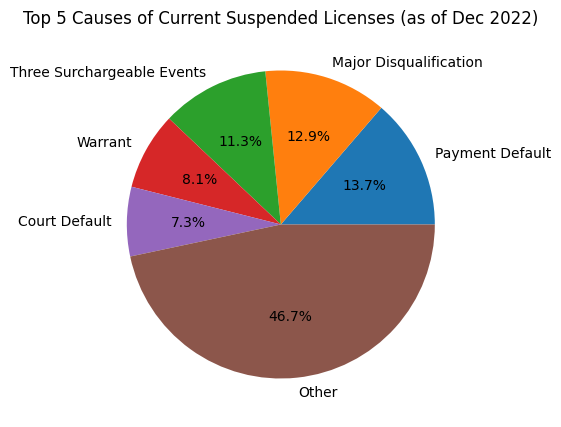

In [25]:
top_num = 5
cur_grouped_sorted = cur_suspended.to_pandas().groupby('Description').size().sort_values(ascending=False)
cur_grouped = cur_grouped_sorted[:top_num]
cur_grouped['Other'] = cur_grouped_sorted[top_num:].sum()

display(cur_grouped)

plt.figure(figsize=(5, 5))
plt.title(f'Top {top_num} Causes of Current Suspended Licenses (as of Dec 2022)')
plt.pie(cur_grouped, labels=[i.title() for i in cur_grouped.index], autopct='%1.1f%%')
plt.savefig(img_path / f'top_{top_num}_suspended_license_causes.png')
plt.show()

In [9]:
default = pl.from_dataframe(cur_suspended).filter((pl.col("Description") == "PAYMENT DEFAULT") & (pl.col("Term") == "Indefinite"))
print(f'{default.shape[0]} suspensions due to payment default, {round(default.shape[0]/cur_suspended.shape[0]*100, 3)}% of {cur_suspended.shape[0]} total suspensions')

94841 suspensions due to payment default, 13.684% of 693100 total suspensions


In [10]:
len(np.unique(cur_suspended['Description'].to_list() + reinstatement['Sanction Description'].to_list()))

197

In [11]:
reasons_path = pathlib.Path.cwd().parent.joinpath('data', 'suspension_reasons_classified.csv')

reasons = pl.read_csv(reasons_path)[['Description', 'dangerous', 'debt_based']]
reasons

Description,dangerous,debt_based
str,bool,bool
"""PAYMENT DEFAUL…",false,true
"""Three Surcharg…",true,false
"""Major Disquali…",true,false
"""Reciprocal Sus…",false,false
"""WARRANT""",false,false
…,…,…
"""RDR __ RESUSP …",false,false
"""CHEMICAL TEST …",false,false
"""CHEAT ON CDL E…",false,false


In [12]:
sus_reason = suspension.join(reasons, on='Description')
sus_reason

Year,Description,Term,dangerous,debt_based
i64,str,str,bool,bool
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
2020,"""Ignition Inter…","""Indefinite""",true,false
2020,"""Operating Unde…","""Definite""",true,false
…,…,…,…,…
2022,"""COMPLAINT REGU…","""Indefinite""",false,false
2022,"""Operating Unde…","""Definite""",true,false
2022,"""Operating Unde…","""Definite""",true,false


In [13]:
dd_by_year = sus_reason.group_by('Year').agg(
    pl.col('Description').count().alias('total_count'),
    pl.col('dangerous').sum().alias('dangerous_count'),
    pl.col('debt_based').sum().alias('debt_based_count'),
    (pl.col('dangerous').sum()/pl.count('Description')*100).alias('dangerous_percentage'), 
    (pl.col('debt_based').sum()/pl.count('Description')*100).alias('debt_based_percentage'),
).sort('Year')
dd_by_year

Year,total_count,dangerous_count,debt_based_count,dangerous_percentage,debt_based_percentage
i64,u32,u32,u32,f64,f64
2020,116841,81765,21142,69.979716,18.094676
2021,111342,63472,20052,57.006341,18.009377
2022,114600,61689,23160,53.829843,20.209424


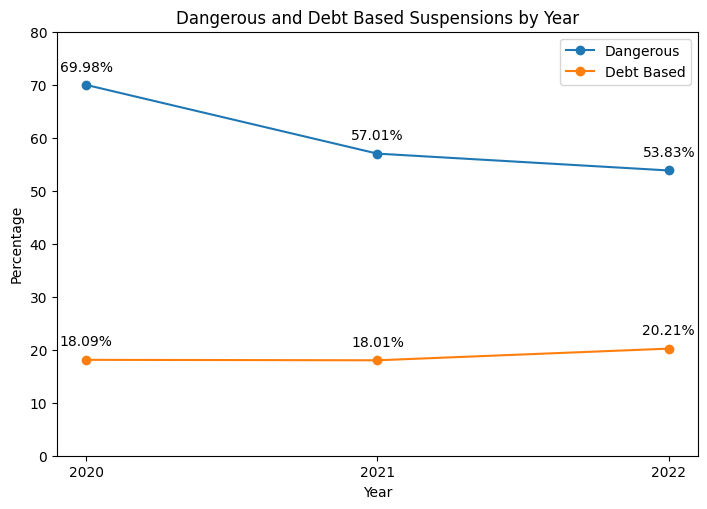

In [14]:
plt.figure(figsize=(7, 5))
plt.title('Dangerous and Debt Based Suspensions by Year')

plt.plot(dd_by_year['Year'], dd_by_year['dangerous_percentage'], label='Dangerous', marker='o')
plt.plot(dd_by_year['Year'], dd_by_year['debt_based_percentage'], label='Debt Based', marker='o')

plt.xticks(dd_by_year['Year'])

for i, v in zip(dd_by_year['Year'], dd_by_year['dangerous_percentage']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v in zip(dd_by_year['Year'], dd_by_year['debt_based_percentage']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
    )

plt.tight_layout()
plt.ylim(0, 80)

plt.xlabel('Year')
plt.ylabel('Percentage')

plt.savefig(img_path / 'dangerous_debt_based_suspensions_by_year.png')
plt.legend()
plt.show()

In [15]:
hypothesis_table = sus_reason.filter((pl.col('dangerous') != True)& pl.col('debt_based'))
hypothesis_table

Year,Description,Term,dangerous,debt_based
i64,str,str,bool,bool
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2020,"""PAYMENT DEFAUL…","""Indefinite""",false,true
…,…,…,…,…
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true
2022,"""PAYMENT DEFAUL…","""Indefinite""",false,true


In [16]:
hypo_group = hypothesis_table.group_by('Year').agg(
    (pl.col('Description').count()/dd_by_year['total_count']*100).alias('percent_by_year'),
    (pl.col('Description').count().alias('total')),
).sort('Year').with_columns(dd_by_year['total_count'])
hypo_group

Year,percent_by_year,total,total_count
i64,f64,u32,u32
2020,18.988342,21142,116841
2021,17.497382,20052,111342
2022,19.821809,23160,114600


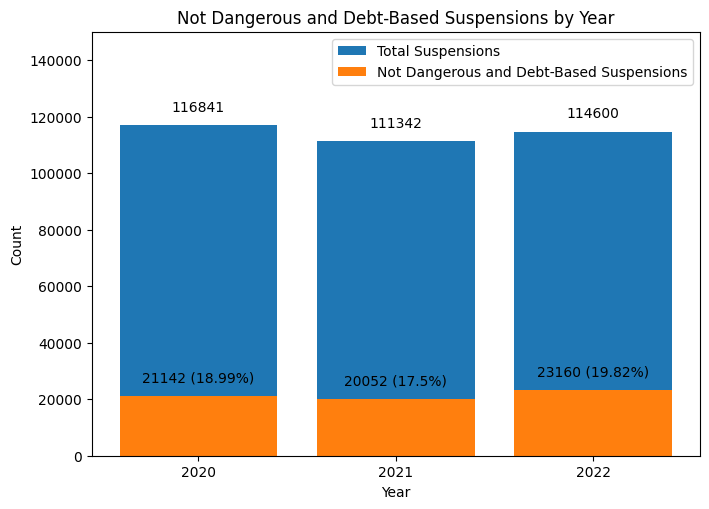

In [17]:
plt.figure(figsize=(7, 5))
plt.title('Not Dangerous and Debt-Based Suspensions by Year')

plt.bar(hypo_group['Year'], hypo_group['total_count'], label='Total Suspensions')
plt.bar(hypo_group['Year'], hypo_group['total'], label='Not Dangerous and Debt-Based Suspensions')

plt.xticks(hypo_group['Year'])

for i, v in zip(hypo_group['Year'], hypo_group['total_count']):
    plt.annotate(
        f'{round(v, 2)}',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v, p in zip(hypo_group['Year'], hypo_group['total'], hypo_group['percent_by_year']):
    plt.annotate(
        f'{round(v, 2)} ({round(p, 2)}%)',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

plt.ylim(0, 150000)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Count')

plt.savefig(img_path / 'safe_debtbased_suspensions.png')
plt.legend()
plt.show()

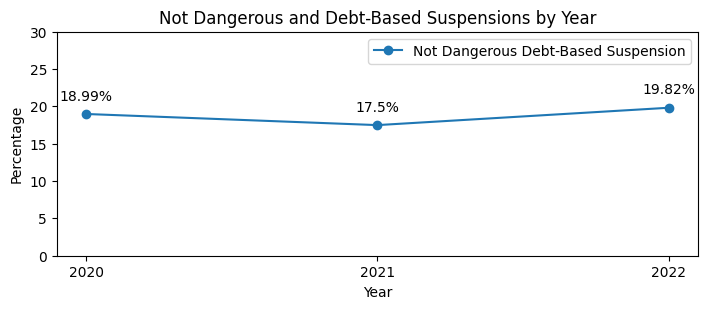

In [18]:
plt.figure(figsize=(7, 3))
plt.title('Not Dangerous and Debt-Based Suspensions by Year')

plt.plot(hypo_group['Year'], hypo_group['percent_by_year'], label='Not Dangerous Debt-Based Suspension', marker='o')

plt.xticks(hypo_group['Year'])

for i, v in zip(hypo_group['Year'], hypo_group['percent_by_year']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )


plt.ylim(0, 30)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Percentage')

plt.savefig(img_path / 'not_dangerous_debt_based_suspensions_by_year.png')
plt.legend()
plt.show()

In [19]:
temp = cur_suspended['Description'].extend(suspension['Description']).extend(reinstatement['Sanction Description'])

# to prevent constant rewrites
if not pathlib.Path.exists(data_path.joinpath('suspension_reasons.csv')):
    temp.value_counts().sort('count', descending=True).to_pandas().to_csv(data_path.joinpath('suspension_reasons.csv'), index=False)

In [20]:
rein_2020 = reinstatement.filter(pl.col('Year Reinstated') == 2020)
rein_2021 = reinstatement.filter(pl.col('Year Reinstated') == 2021)
rein_2022 = reinstatement.filter(pl.col('Year Reinstated') == 2022)

In [21]:
rein_2020.group_by('Sanction Description').agg(
    pl.count('Sanction Description').alias('count'),
    (pl.count('Sanction Description')/rein_2020.shape[0]).alias('percent')
    ).sort('count', descending=True).head(10)

Sanction Description,count,percent
str,u32,f64
"""PAYMENT DEFAUL…",17393,0.261117
"""Three Surcharg…",12764,0.191623
"""NRVC Withdrawa…",8621,0.129425
"""Operating Unde…",3502,0.052575
"""Seven Surcharg…",3285,0.049317
"""NON-PAYMENT OF…",2919,0.043822
"""WARRANT""",1929,0.02896
"""ADMIN PER SE""",1831,0.027488
"""Chemical Test …",1568,0.02354


In [22]:
rein_2021.group_by('Sanction Description').agg(
    pl.count('Sanction Description').alias('count'),
    (pl.count('Sanction Description')/rein_2021.shape[0]).alias('percent')
    ).sort('count', descending=True).head(10)

Sanction Description,count,percent
str,u32,f64
"""PAYMENT DEFAUL…",11560,0.215282
"""Three Surcharg…",9698,0.180606
"""NRVC Withdrawa…",3782,0.070432
"""Operating Unde…",3448,0.064212
"""Reciprocal Sus…",3050,0.0568
"""Seven Surcharg…",2496,0.046483
"""NON-PAYMENT OF…",2186,0.04071
"""WARRANT""",1644,0.030616
"""Chemical Test …",1630,0.030356


In [23]:
rein_2022.group_by('Sanction Description').agg(
    pl.count('Sanction Description').alias('count'),
    (pl.count('Sanction Description')/rein_2022.shape[0]).alias('percent')
    ).sort('count', descending=True).head(10)

Sanction Description,count,percent
str,u32,f64
"""PAYMENT DEFAUL…",4908,0.175964
"""Three Surcharg…",4067,0.145812
"""Reciprocal Sus…",2545,0.091245
"""Operating Unde…",2487,0.089165
"""Chemical Test …",1395,0.050014
"""NON-PAYMENT OF…",1230,0.044099
"""Seven Surcharg…",1057,0.037896
"""ADMIN PER SE""",1004,0.035996
"""NRVC Withdrawa…",809,0.029005


In [42]:
reinstatement.head(10)

Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
i64,str,str,str,str,str


In [51]:
rein_df= reinstatement.to_pandas()
rein_df[
    (rein_df['Days Sus/Rev'] != 'INDEFINITE') & (rein_df['Days Sus/Rev'] != 'Definite') & (rein_df['Days Sus/Rev'] != 'Lifetime')
    ].dropna(subset=['Days Sus/Rev']).astype({'Days Sus/Rev': 'int64'})[
        ['Year Reinstated', 'Sanction Description', 'Days Sus/Rev']
        ].groupby(['Year Reinstated', 'Sanction Description']).agg([np.mean, np.median, np.std, np.min, np.max])

Days Sus/Rev  \
                                                                    mean   
Year Reinstated Sanction Description                                       
2020            94C27 __ POSS HYPO SYRINGE                    365.000000   
                94C32BA __ POSSESS CLS C/INTENT              1095.000000   
                94C32J __ 1000 FEET SCHOOL                   1808.534884   
                94C33 B __ UT FALSE PRES                      730.000000   
                94C33 __ FALSE PRESCRIPTION                   730.000000   
...                                                                  ...   
2022            VANDALIZE PROPERTY c266 §126A                 365.000000   
                W00 - Non-ACD withdrawal                    14458.500000   
                WARRANT                                      1251.643491   
                WINDOW OBSTRUCTED/NONTRANSPARENT * c90 §9D     90.000000   
                Youth Alcohol Program Suspension              135.492308   

                                                                     \
                                                             median   
Year Reinstated Sanction Description                                  
2020            94C27 __ POSS HYPO SYRINGE                    365.0   
                94C32BA __ POSSESS CLS C/INTENT              1095.0   
                94C32J __ 1000 FEET SCHOOL                   1825.0   
                94C33 B __ UT FALSE PRES                      730.0   
                94C33 __ FALSE PRESCRIPTION                   730.0   
...                                                             ...   
2022            VANDALIZE PROPERTY c266 §126A                 365.0   
                W00 - Non-ACD withdrawal                    14467.0   
                WARRANT                                       600.0   
                WINDOW OBSTRUCTED/NONTRANSPARENT * c90 §9D     90.0   
                Youth Alcohol Program Suspension              180.0   

                                                                         \
                                                                    std   
Year Reinstated Sanction Description                                      
2020            94C27 __ POSS HYPO SYRINGE                     0.000000   
                94C32BA __ POSSESS CLS C/INTENT                0.000000   
                94C32J __ 1000 FEET SCHOOL                   107.968988   
                94C33 B __ UT FALSE PRES                       0.000000   
                94C33 __ FALSE PRESCRIPTION                         NaN   
...                                                                 ...   
2022            VANDALIZE PROPERTY c266 §126A                  0.000000   
                W00 - Non-ACD withdrawal                     565.808271   
                WARRANT                                     1632.732792   
                WINDOW OBSTRUCTED/NONTRANSPARENT * c90 §9D          NaN   
                Youth Alcohol Program Suspension              97.169256   

                                                                          
                                                              min    max  
Year Reinstated Sanction Description                                      
2020            94C27 __ POSS HYPO SYRINGE                    365    365  
                94C32BA __ POSSESS CLS C/INTENT              1095   1095  
                94C32J __ 1000 FEET SCHOOL                   1117   1825  
                94C33 B __ UT FALSE PRES                      730    730  
                94C33 __ FALSE PRESCRIPTION                   730    730  
...                                                           ...    ...  
2022            VANDALIZE PROPERTY c266 §126A                 365    365  
                W00 - Non-ACD withdrawal                    13890  15010  
                WARRANT                                         0   7733  
                WINDOW OBSTRUCTED/NONTRANSPARENT 